In [11]:
# -*- coding: utf-8 -*-
import os
import xarray as xr
import pandas as pd
import numpy as np
from pymannkendall import original_test
from scipy.stats import linregress

# ========= 输出路径 =========
OUT_DIR = r"C:\greenland\1995bu\fig4"
os.makedirs(OUT_DIR, exist_ok=True)

# ========= 文件路径 =========
files = {
    "t2m":  r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5LANDfeature_greenland.nc",
    "strd": r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5LANDfeature_greenland.nc",
    "ssrd": r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5LANDfeature_greenland202209.nc",
    "rf":   r"C:\greenland\sf_tp_rf.nc",
    "tcc":  r"C:\Users\greenlandProject\ERA5LAND\greenland_tcc_full.nc",
}

# ========= 函数 =========
def calc_summer_mean(ds, varname):
    """提取夏季 (JJA) 年度均值"""
    time_name = "valid_time" if "valid_time" in ds.coords else "time"
    da = ds[varname]
    da = da.assign_coords(time=ds[time_name])
    da = da.swap_dims({time_name: "time"})
    da["month"] = da["time"].dt.month
    da["year"] = da["time"].dt.year
    da_summer = da.where(da["month"].isin([6,7,8]), drop=True)
    summer_mean = da_summer.groupby("year").mean(dim="time", skipna=True)
    return summer_mean

def mk_trend_per_decade(y):
    y = np.array(y)
    if np.isnan(y).all():
        return np.nan
    try:
        res = original_test(y)
        return res.slope * 10
    except Exception:
        return np.nan

def compute_grid_mean_trend(da):
    """计算每格点均值 + MK趋势"""
    lat_name = "latitude" if "latitude" in da.coords else "lat"
    lon_name = "longitude" if "longitude" in da.coords else "lon"
    lats = da[lat_name].values
    lons = da[lon_name].values
    
    mean_map = da.mean(dim="year", skipna=True)
    trend_map = xr.apply_ufunc(
        mk_trend_per_decade,
        da,
        input_core_dims=[["year"]],
        vectorize=True,
        dask="parallelized",
        output_dtypes=[float]
    )
    
    LAT, LON = np.meshgrid(lats, lons, indexing="ij")
    df = pd.DataFrame({
        "lat": LAT.flatten(),
        "lon": LON.flatten(),
        "mean": mean_map.values.flatten(),
        "trend_per_decade": trend_map.values.flatten()
    })
    return df

def compute_sliding_trend(years, series):
    n = len(years)
    trend_matrix = np.full((n, n), np.nan)
    for i in range(n - 1):
        for j in range(i + 1, n):
            y = series[i:j+1]
            if np.isnan(y).sum() < len(y) - 2:
                slope, _, _, _, _ = linregress(np.arange(len(y)), y)
                trend_matrix[i, j] = slope
    df = pd.DataFrame(trend_matrix, index=years, columns=years)
    return df

# ========= 主循环 =========
for var, path in files.items():
    print(f"\n===== Processing {var} =====")
    
    # ✅ 检查CSV是否已存在（只检查一个，因为两个总是同时生成）
    out_meantrend = os.path.join(OUT_DIR, f"Greenland_{var}_MeanTrend.csv")
    out_slide = os.path.join(OUT_DIR, f"Greenland_{var}_SlidingTrend.csv")
    
    if os.path.exists(out_meantrend):
        print(f"⏭️  {var} 的CSV已存在，跳过")
        continue
    
    # 打开数据集
    ds = xr.open_dataset(path)
    if var not in ds.data_vars:
        print(f"⚠️  Variable {var} not found in {path}")
        ds.close()
        continue
    
    da = calc_summer_mean(ds, var)
    ds.close()
    print(f"✅ Summer mean shape: {da.shape}")
    
    # ---- 均值 + MK 趋势 ----
    print("⏳ Calculating MK trend per grid...")
    df_mt = compute_grid_mean_trend(da)
    df_mt.to_csv(out_meantrend, index=False)
    print(f"💾 Saved: {out_meantrend}")
    
    # ---- 滑动趋势 ----
    lat_name = "latitude" if "latitude" in da.coords else "lat"
    lon_name = "longitude" if "longitude" in da.coords else "lon"
    area_mean = da.mean(dim=[lat_name, lon_name], skipna=True).values
    years = da.year.values
    
    print("⏳ Calculating sliding trends...")
    df_slide = compute_sliding_trend(years, area_mean)
    df_slide.to_csv(out_slide, index=True)
    print(f"💾 Saved: {out_slide}")

print("\n✅ 全部5个变量（t2m, strd, ssrd, rf, tcc）处理完成！结果保存在 C:\\greenland\\1995bu\\fig4")


===== Processing t2m =====
⏭️  t2m 的CSV已存在，跳过

===== Processing strd =====
⏭️  strd 的CSV已存在，跳过

===== Processing ssrd =====
✅ Summer mean shape: (75, 239, 612)
⏳ Calculating MK trend per grid...
💾 Saved: C:\greenland\1995bu\fig4\Greenland_ssrd_MeanTrend.csv
⏳ Calculating sliding trends...
💾 Saved: C:\greenland\1995bu\fig4\Greenland_ssrd_SlidingTrend.csv

===== Processing rf =====
⏭️  rf 的CSV已存在，跳过

===== Processing tcc =====
⏭️  tcc 的CSV已存在，跳过

✅ 全部5个变量（t2m, strd, ssrd, rf, tcc）处理完成！结果保存在 C:\greenland\1995bu\fig4


In [2]:
# -*- coding: utf-8 -*-
import os
import xarray as xr
import pandas as pd
import numpy as np
from pymannkendall import original_test
from scipy.stats import linregress

# ========= 输出路径 =========
OUT_DIR = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile"
os.makedirs(OUT_DIR, exist_ok=True)

# ========= 文件路径 =========
files = {
    "sf":   r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\sf_tp_rf.nc",
    "tp":   r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\sf_tp_rf.nc",
    "hcc":  r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\GreenlandhclcVIMF.nc",
    "lcc":  r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\GreenlandhclcVIMF.nc",
    "vimdf": r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\GreenlandhclcVIMF.nc",
}

# ========= 函数 =========
def calc_summer_mean(ds, varname):
    """提取每年夏季(JJA)均值"""
    time_name = "valid_time" if "valid_time" in ds.coords else "time"
    da = ds[varname]
    da = da.assign_coords(time=ds[time_name])
    da = da.swap_dims({time_name: "time"})
    da["month"] = da["time"].dt.month
    da["year"] = da["time"].dt.year
    da_summer = da.where(da["month"].isin([6,7,8]), drop=True)
    da_summer_mean = da_summer.groupby("year").mean(dim="time", skipna=True)
    return da_summer_mean

def mk_trend_per_decade(y):
    """对单点时间序列做MK趋势检验"""
    y = np.array(y)
    if np.isnan(y).all():
        return np.nan
    try:
        res = original_test(y)
        return res.slope * 10
    except Exception:
        return np.nan

def compute_grid_mean_trend(da):
    """计算每格点多年均值 + MK趋势"""
    lat_name = "latitude" if "latitude" in da.coords else "lat"
    lon_name = "longitude" if "longitude" in da.coords else "lon"
    lats = da[lat_name].values
    lons = da[lon_name].values
    
    mean_map = da.mean(dim="year", skipna=True)
    trend_map = xr.apply_ufunc(
        mk_trend_per_decade,
        da,
        input_core_dims=[["year"]],
        vectorize=True,
        dask="parallelized",
        output_dtypes=[float]
    )
    
    LAT, LON = np.meshgrid(lats, lons, indexing="ij")
    df = pd.DataFrame({
        "lat": LAT.flatten(),
        "lon": LON.flatten(),
        "mean": mean_map.values.flatten(),
        "trend_per_decade": trend_map.values.flatten()
    })
    return df

def compute_sliding_trend(years, series):
    """计算滑动趋势矩阵"""
    n = len(years)
    trend_matrix = np.full((n, n), np.nan)
    for i in range(n - 1):
        for j in range(i + 1, n):
            y = series[i:j+1]
            if np.isnan(y).sum() < len(y) - 2:
                slope, _, _, _, _ = linregress(np.arange(len(y)), y)
                trend_matrix[i, j] = slope
    df = pd.DataFrame(trend_matrix, index=years, columns=years)
    return df

# ========= 主循环 =========
for var, path in files.items():
    print(f"\n===== Processing {var} =====")
    
    out_meantrend = os.path.join(OUT_DIR, f"Greenland_{var}_MeanTrend.csv")
    out_slide = os.path.join(OUT_DIR, f"Greenland_{var}_SlidingTrend.csv")
    
    if os.path.exists(out_meantrend):
        print(f"⏭️  {var} 的CSV已存在，跳过")
        continue

    # 打开文件
    ds = xr.open_dataset(path)
    if var not in ds.data_vars:
        print(f"⚠️  Variable {var} not found in {path}")
        ds.close()
        continue

    da = calc_summer_mean(ds, var)
    ds.close()
    print(f"✅ Summer mean shape: {da.shape}")

    # ---- 均值 + MK趋势 ----
    print("⏳ Calculating MK trend per grid...")
    df_mt = compute_grid_mean_trend(da)
    df_mt.to_csv(out_meantrend, index=False)
    print(f"💾 Saved: {out_meantrend}")

    # ---- 滑动趋势 ----
    lat_name = "latitude" if "latitude" in da.coords else "lat"
    lon_name = "longitude" if "longitude" in da.coords else "lon"
    area_mean = da.mean(dim=[lat_name, lon_name], skipna=True).values
    years = da.year.values

    print("⏳ Calculating sliding trends...")
    df_slide = compute_sliding_trend(years, area_mean)
    df_slide.to_csv(out_slide, index=True)
    print(f"💾 Saved: {out_slide}")

print("\n✅ 新的5个变量（sf, tp, hcc, lcc, vimdf）处理完成！结果保存在 C:\\Users\\greenlandProject\\ERA5LAND\\ProcessFile")



===== Processing sf =====
⏭️  sf 的CSV已存在，跳过

===== Processing tp =====
⏭️  tp 的CSV已存在，跳过

===== Processing hcc =====
⏭️  hcc 的CSV已存在，跳过

===== Processing lcc =====
⏭️  lcc 的CSV已存在，跳过

===== Processing vimdf =====
✅ Summer mean shape: (76, 95, 244)
⏳ Calculating MK trend per grid...
💾 Saved: C:\Users\greenlandProject\ERA5LAND\ProcessFile\Greenland_vimdf_MeanTrend.csv
⏳ Calculating sliding trends...
💾 Saved: C:\Users\greenlandProject\ERA5LAND\ProcessFile\Greenland_vimdf_SlidingTrend.csv

✅ 新的5个变量（sf, tp, hcc, lcc, vimdf）处理完成！结果保存在 C:\Users\greenlandProject\ERA5LAND\ProcessFile


In [1]:
import numpy as np
import pandas as pd
import xarray as xr
from sklearn.linear_model import LinearRegression

# ===== 路径 (Path - 请根据你的实际路径修改) =====
nc_path = r"C:\greenland\1995bu\Greenland_albedo1950-2024Summer.nc"
output_path = r"C:\greenland\1995bu\fig4\Greenland_alb_SlidingTrend.csv"

# ===== 1. 读取并计算格陵兰平均 Albedo =====
try:
    ds = xr.open_dataset(nc_path)
except FileNotFoundError:
    print(f"ERROR: File not found at {nc_path}. Please check the path.")
    exit()

# 自动识别包含"albedo"的变量名
varname = [v for v in ds.data_vars if "albedo" in v.lower()][0]
da = ds[varname]
albedo_mean = da.mean(dim=("lat", "lon"), skipna=True)

# ===== 2. 识别时间维度 =====
time_values = albedo_mean["time"].values
if np.issubdtype(time_values.dtype, np.number):
    years = np.array(time_values).astype(int)
else:
    # 提取年份
    years = pd.to_datetime(time_values).year
vals = albedo_mean.values
print(f"✅ Data range: {years.min()}–{years.max()} ({len(years)} years)")

# ===== 3. 计算滑动趋势矩阵（右上角结构） =====
n = len(years)
# 初始化一个全为 NaN 的矩阵
trend_matrix = np.full((n, n), np.nan) 

# 外层循环: Start Year index (对应矩阵的行 i)
for i in range(n): 
    # 内层循环: End Year index (对应矩阵的列 j)
    # 确保时段长度至少为 3 年 (j - i + 1 >= 3)，所以 j >= i + 2
    for j in range(i + 2, n): 
        
        # 截取从 i 到 j (包含 j) 的年份和数据
        x = np.array(years[i:j+1]).reshape(-1, 1) # 时间变量 (自变量)
        y = vals[i:j+1]                           # Albedo 值 (因变量)
        
        # 确保有足够多的有限值来进行线性回归 (至少2个点，但我们要求至少3年)
        if np.isfinite(y).sum() >= 2: 
            model = LinearRegression().fit(x, y)
            # 将趋势值存入矩阵的 [Start Year Index, End Year Index]，即右上角
            trend_matrix[i, j] = model.coef_[0] 
        else:
            # 如果数据点不足，保持为 NaN
            trend_matrix[i, j] = np.nan

# ===== 4. 创建 DataFrame 并保存为 CSV =====
# 创建 DataFrame，行索引和列索引都是年份
df = pd.DataFrame(trend_matrix, index=years, columns=years)

# 保存为 CSV 文件
df.to_csv(output_path, index=True, na_rep='')
print(f"✅ CSV file saved to: {output_path}")

# 显示前几行预览
print("\n前5行5列预览:")
print(df.iloc[:5, :5])

ds.close() # 关闭 xarray 数据集


✅ Data range: 1950–2024 (75 years)
✅ CSV file saved to: C:\greenland\1995bu\fig4\Greenland_alb_SlidingTrend.csv

前5行5列预览:
      1950  1951      1952      1953      1954
1950   NaN   NaN  0.004835  0.002649  0.002529
1951   NaN   NaN       NaN -0.001646  0.000322
1952   NaN   NaN       NaN       NaN  0.002311
1953   NaN   NaN       NaN       NaN       NaN
1954   NaN   NaN       NaN       NaN       NaN


In [ ]:
# -*- coding: utf-8 -*-
import os
import xarray as xr
import pandas as pd
import numpy as np
from pymannkendall import original_test

# ========= 文件路径与输出路径 =========
NC_PATH  = r"C:\greenland\1995bu\Greenland_albedo1950-2024Summer.nc"
OUT_PATH = r"C:\greenland\1995bu\fig4\Greenland_alb_MeanTrend.csv"

# ========= 函数定义 =========
def mk_trend_per_decade(y):
    """对每个像元时间序列做 Mann-Kendall 趋势检验，返回每十年变化率"""
    y = np.array(y, dtype=float)
    if np.isnan(y).all():
        return np.nan
    try:
        res = original_test(y)
        return res.slope * 10
    except Exception:
        return np.nan

def compute_mean_trend(da):
    """计算均值和MK趋势"""
    lat = da["lat"].values
    lon = da["lon"].values

    mean_map = da.mean(dim="time", skipna=True)
    trend_map = xr.apply_ufunc(
        mk_trend_per_decade,
        da,
        input_core_dims=[["time"]],
        vectorize=True,
        dask="parallelized",
        output_dtypes=[float]
    )

    LAT, LON = np.meshgrid(lat, lon, indexing="ij")
    df = pd.DataFrame({
        "lat": LAT.flatten(),
        "lon": LON.flatten(),
        "mean": mean_map.values.flatten(),
        "trend_per_decade": trend_map.values.flatten()
    })
    return df

# ========= 主程序 =========
print("===== Processing Greenland albedo =====")

ds = xr.open_dataset(NC_PATH)
da = ds["albedo"]

print(f"✅ 数据读取完成: {da.shape}, dims={list(da.dims)}")

df = compute_mean_trend(da)

# ========= 输出 =========
os.makedirs(os.path.dirname(OUT_PATH), exist_ok=True)
df.to_csv(OUT_PATH, index=False)
print(f"💾 已保存: {OUT_PATH}")
print("\n✅ 完成！文件内容包含 lat, lon, mean, trend_per_decade 四列。")



────────────────────────────────────────────────────────────────────────────────
【文件路径】
────────────────────────────────────────────────────────────────────────────────
C:\greenland\1995bu\Greenland_albedo1950-2024Summer.nc

────────────────────────────────────────────────────────────────────────────────
【基本打开（decode_cf=False / True）】
────────────────────────────────────────────────────────────────────────────────

────────────────────────────────────────────────────────────────────────────────
【数据集基本信息（decode_cf=False）】
────────────────────────────────────────────────────────────────────────────────
  data_vars: ['albedo']
  coords:    ['lat', 'lon', 'time']
  dims:      {'lat': 237, 'lon': 612, 'time': 75}
  dataset attrs (0):
    (no attrs)

────────────────────────────────────────────────────────────────────────────────
【数据集基本信息（decode_cf=True）】
────────────────────────────────────────────────────────────────────────────────
  data_vars: ['albedo']
  coords:    ['lat', 'lon', 'tim

C:\Users\11823\AppData\Local\Temp\ipykernel_63824\2128983320.py:148: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  print(f"  dims:      {dict(ds_raw.dims)}")
C:\Users\11823\AppData\Local\Temp\ipykernel_63824\2128983320.py:155: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  print(f"  dims:      {dict(ds_cf.dims)}")


C:\Users\11823\AppData\Local\Temp\ipykernel_35412\2541842929.py:269: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Arial.
  plt.savefig(SAVE_PATH, dpi=300, bbox_inches="tight")
c:\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


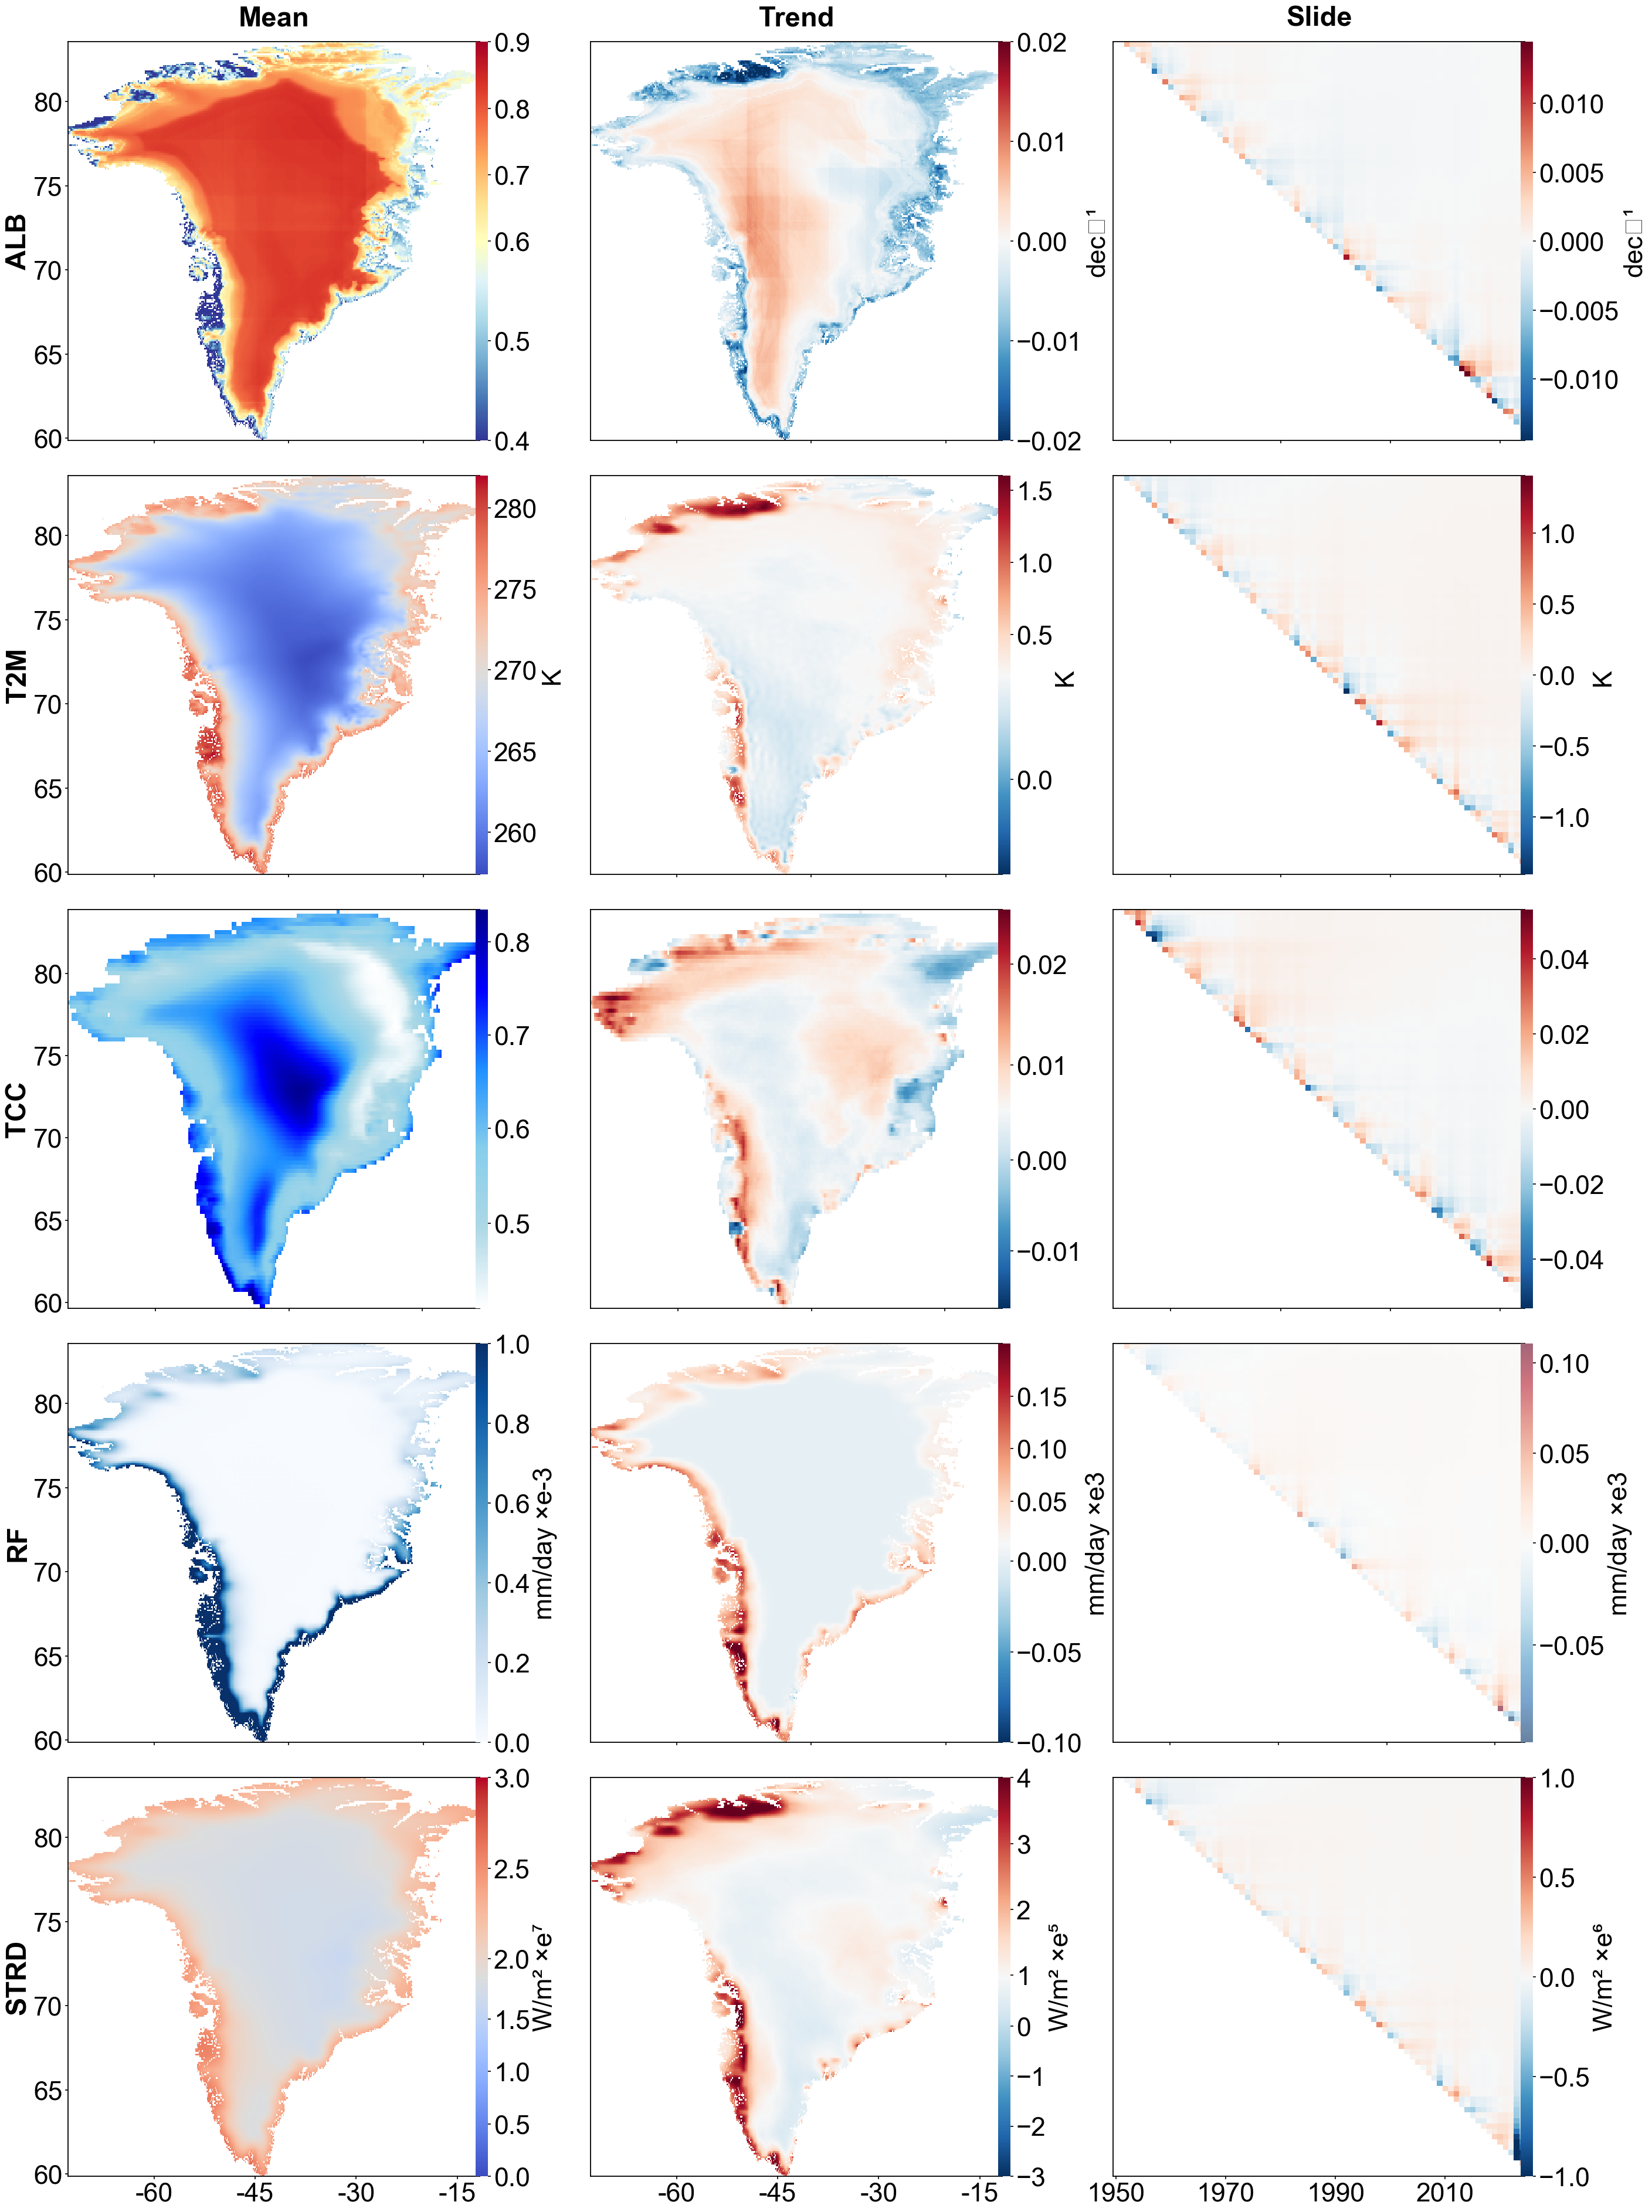

In [1]:
# -*- coding: utf-8 -*-
"""
Final 5×3 Greenland Climate Panel (alb / t2m / tcc / rf / strd)
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm, Normalize, LinearSegmentedColormap
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.colors as mcolors
from matplotlib.ticker import MaxNLocator, FormatStrFormatter

# ===== 参数区 =====
FONT_SIZE = 32
TITLE_SIZE = FONT_SIZE + 2
HSPACE = 0.015
WSPACE = 0.07
TOP_ALIGN = 0.96
DATA_DIR = r"C:\greenland\1995bu\fig4"
SAVE_PATH = r"C:\greenland\1995bu\fig4\Fig4_5x3panel.png"

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": FONT_SIZE,
    "axes.linewidth": 1.3,
    "xtick.major.width": 1.2,
    "ytick.major.width": 1.2
})

fig = plt.figure(figsize=(27, 40))  # 增高画布
VARS = ["alb", "t2m", "tcc", "rf", "strd"]
COL_NAMES = ["Mean", "Trend", "Slide"]

n_rows, n_cols = len(VARS), len(COL_NAMES)
left_margin, right_margin, bottom_margin = 0.05, 0.97, 0.05
total_width = right_margin - left_margin
available_width = total_width - (n_cols - 1) * WSPACE
w = available_width / n_cols
h = (TOP_ALIGN - bottom_margin - (n_rows - 1) * HSPACE) / n_rows

axes = []

# ========== 绘图循环 ==========
for i, var in enumerate(VARS):
    for j, col in enumerate(COL_NAMES):
        left = left_margin + j * (w + WSPACE)
        bottom = TOP_ALIGN - (i + 1) * h - i * HSPACE
        ax = fig.add_axes([left, bottom, w, h])
        axes.append(ax)
        CBAR_WIDTH, CBAR_PAD = "3%", 0.02

        # ================= ALBEDO =================
        if var == "alb":
            meantrend_csv = f"{DATA_DIR}\\Greenland_alb_MeanTrend.csv"
            sliding_csv   = f"{DATA_DIR}\\Greenland_alb_SlidingTrend.csv"

            df = pd.read_csv(meantrend_csv).dropna(subset=["mean", "trend_per_decade"])
            mean_grid  = df.pivot(index="lat", columns="lon", values="mean").sort_index(ascending=True)
            trend_grid = df.pivot(index="lat", columns="lon", values="trend_per_decade").sort_index(ascending=True)
            mean_grid = mean_grid.reindex(sorted(mean_grid.columns), axis=1)
            trend_grid = trend_grid.reindex(sorted(trend_grid.columns), axis=1)

            slide = pd.read_csv(sliding_csv, index_col=0)
            lats, lons = mean_grid.index.values.astype(float), mean_grid.columns.values.astype(float)
            years, slide_years = slide.columns.astype(int).values, slide.index.astype(int).values
            vals = slide.to_numpy(dtype=float)
            mask = np.tril(np.ones_like(vals, dtype=bool), -1)
            vals_masked = np.ma.array(vals, mask=mask)

            mean_cmap = plt.cm.RdYlBu_r
            trend_cmap = plt.cm.RdBu_r

            if col == "Mean":
                im = ax.pcolormesh(lons, lats, mean_grid.values,
                                   cmap=mean_cmap,
                                   norm=TwoSlopeNorm(vmin=0.4, vcenter=0.6, vmax=0.9),
                                   shading="auto")
                label = " "
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_grid.values,
                                   cmap=trend_cmap,
                                   norm=TwoSlopeNorm(vmin=-0.02, vcenter=0, vmax=0.02),
                                   shading="auto")
                label = "dec⁻¹"
            else:
                vmax_slide = np.nanmax(np.abs(vals_masked))
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap=trend_cmap,
                                   norm=TwoSlopeNorm(vmin=-vmax_slide, vcenter=0, vmax=vmax_slide),
                                   shading="auto")
                ax.invert_yaxis()
                label = "dec⁻¹"

        # ================= 其他变量直接复用原逻辑 =================
        elif var == "t2m":
            meantrend_csv = f"{DATA_DIR}\\Greenland_t2m_MeanTrend.csv"
            sliding_csv   = f"{DATA_DIR}\\Greenland_t2m_SlidingTrend.csv"
            df = pd.read_csv(meantrend_csv).dropna(subset=["mean", "trend_per_decade"])
            mean_grid  = df.pivot(index="lat", columns="lon", values="mean").sort_index(ascending=True)
            trend_grid = df.pivot(index="lat", columns="lon", values="trend_per_decade").sort_index(ascending=True)
            mean_grid = mean_grid.reindex(sorted(mean_grid.columns), axis=1)
            trend_grid = trend_grid.reindex(sorted(trend_grid.columns), axis=1)
            slide = pd.read_csv(sliding_csv, index_col=0)
            lats, lons = mean_grid.index.values.astype(float), mean_grid.columns.values.astype(float)
            years, slide_years = slide.columns.astype(int).values, slide.index.astype(int).values
            vals = slide.to_numpy(dtype=float)
            mask = np.tril(np.ones_like(vals, dtype=bool), -1)
            vals_masked = np.ma.array(vals, mask=mask)
            TREND_VMIN, TREND_VCENTER, TREND_VMAX = -0.2, 0.22, 1.6
            if col == "Mean":
                im = ax.pcolormesh(lons, lats, mean_grid.values, cmap="coolwarm", shading="auto")
                label = "K"
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_grid.values, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=TREND_VMIN, vcenter=TREND_VCENTER, vmax=TREND_VMAX),
                                   shading="auto")
                label = "K "
            else:
                vmax_slide = np.nanmax(np.abs(vals_masked))
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-vmax_slide, vcenter=0, vmax=vmax_slide),
                                   shading="auto")
                ax.invert_yaxis()
                label = "K "

        elif var == "tcc":
            meantrend_csv = f"{DATA_DIR}\\Greenland_tcc_MeanTrend.csv"
            sliding_csv   = f"{DATA_DIR}\\Greenland_tcc_SlidingTrend.csv"
            df = pd.read_csv(meantrend_csv).dropna(subset=["mean", "trend_per_decade"])
            mean_grid  = df.pivot(index="lat", columns="lon", values="mean").sort_index(ascending=True)
            trend_grid = df.pivot(index="lat", columns="lon", values="trend_per_decade").sort_index(ascending=True)
            mean_grid = mean_grid.reindex(sorted(mean_grid.columns), axis=1)
            trend_grid = trend_grid.reindex(sorted(trend_grid.columns), axis=1)
            slide = pd.read_csv(sliding_csv, index_col=0)
            lats, lons = mean_grid.index.values.astype(float), mean_grid.columns.values.astype(float)
            years, slide_years = slide.columns.astype(int).values, slide.index.astype(int).values
            vals = slide.to_numpy(dtype=float)
            mask = np.tril(np.ones_like(vals, dtype=bool), -1)
            vals_masked = np.ma.array(vals, mask=mask)
            colors_cloud = ['white','lightblue','skyblue','dodgerblue','blue','darkblue']
            cmap_cloud = LinearSegmentedColormap.from_list('cloud', colors_cloud)
            vcenter_mean = 0.62
            if col == "Mean":
                im = ax.pcolormesh(lons, lats, mean_grid.values, cmap=cmap_cloud,
                                   norm=TwoSlopeNorm(vmin=np.nanmin(mean_grid), vcenter=vcenter_mean, vmax=np.nanmax(mean_grid)),
                                   shading="auto")
                label = ""
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_grid.values, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=np.nanmin(trend_grid), vcenter=np.nanmedian(trend_grid), vmax=np.nanmax(trend_grid)),
                                   shading="auto")
                label = " "
            else:
                vmax_slide = np.nanmax(np.abs(vals_masked))
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-vmax_slide, vcenter=0, vmax=vmax_slide),
                                   shading="auto")
                ax.invert_yaxis()
                label = " "

        elif var == "rf":
            meantrend_csv = f"{DATA_DIR}\\Greenland_rf_MeanTrend.csv"
            sliding_csv   = f"{DATA_DIR}\\Greenland_rf_SlidingTrend.csv"
            df = pd.read_csv(meantrend_csv).dropna(subset=["mean", "trend_per_decade"])
            mean_grid  = df.pivot(index="lat", columns="lon", values="mean").sort_index(ascending=True)
            trend_grid = df.pivot(index="lat", columns="lon", values="trend_per_decade").sort_index(ascending=True)
            mean_grid = mean_grid.reindex(sorted(mean_grid.columns), axis=1)
            trend_grid = trend_grid.reindex(sorted(trend_grid.columns), axis=1)
            slide = pd.read_csv(sliding_csv, index_col=0)
            lats, lons = mean_grid.index.values.astype(float), mean_grid.columns.values.astype(float)
            years, slide_years = slide.columns.astype(int).values, slide.index.astype(int).values
            mean_scaled = mean_grid.values * 1e3
            trend_scaled = trend_grid.values * 1e3
            vals = slide.to_numpy(dtype=float) * 1e3
            mask = np.tril(np.ones_like(vals, dtype=bool), -1)
            vals_masked = np.ma.array(vals, mask=mask)
            if col == "Mean":
                im = ax.pcolormesh(lons, lats, mean_scaled, cmap="Blues",
                                   norm=Normalize(vmin=0, vmax=1), shading="auto")
                label = r"mm/day ×e-3"
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_scaled, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-0.1, vcenter=0.01, vmax=0.2),
                                   shading="auto")
                label = r"mm/day ×e3"
            else:
                cmap_slide = plt.cm.RdBu_r
                colors_slide = cmap_slide(np.linspace(0,1,256)); colors_slide[:,-1]=0.6
                cmap_slide_light = mcolors.ListedColormap(colors_slide)
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap=cmap_slide_light,
                                   norm=TwoSlopeNorm(vmin=np.nanmin(vals_masked), vcenter=0, vmax=np.nanmax(vals_masked)),
                                   shading="auto")
                ax.invert_yaxis()
                label = r"mm/day ×e3"

        elif var == "strd":
            meantrend_csv = f"{DATA_DIR}\\Greenland_strd_MeanTrend.csv"
            sliding_csv   = f"{DATA_DIR}\\Greenland_strd_SlidingTrend.csv"
            df = pd.read_csv(meantrend_csv).dropna(subset=["mean", "trend_per_decade"])
            df["lat"] = pd.to_numeric(df["lat"], errors="coerce")
            df["lon"] = pd.to_numeric(df["lon"], errors="coerce")
            df = df.dropna(subset=["lat","lon"])
            mean_grid  = df.pivot(index="lat", columns="lon", values="mean").sort_index(ascending=True)
            trend_grid = df.pivot(index="lat", columns="lon", values="trend_per_decade").sort_index(ascending=True)
            mean_grid  = mean_grid.reindex(sorted(mean_grid.columns), axis=1)
            trend_grid = trend_grid.reindex(sorted(trend_grid.columns), axis=1)
            trend_grid = trend_grid / 1e5
            lats = mean_grid.index.values.astype(float)
            lons = mean_grid.columns.values.astype(float)
            MEAN_VMIN, MEAN_VMAX = 0, 3
            TREND_VMIN, TREND_VMAX = -3, 4
            MEAN_VCENTER  = float(np.nanmedian(mean_grid.values / 1e7))
            TREND_VCENTER = float(np.nanmedian(trend_grid.values))
            eps = 1e-9
            MEAN_VCENTER = np.clip(MEAN_VCENTER, MEAN_VMIN+eps, MEAN_VMAX-eps)
            TREND_VCENTER = np.clip(TREND_VCENTER, TREND_VMIN+eps, TREND_VMAX-eps)
            slide = pd.read_csv(sliding_csv, index_col=0)
            years, slide_years = slide.columns.astype(int).values, slide.index.astype(int).values
            vals = slide.to_numpy(dtype=float) / 1e6
            mask = np.tril(np.ones_like(vals, dtype=bool), -1)
            vals_masked = np.ma.array(vals, mask=mask)
            if col == "Mean":
                norm_mean = TwoSlopeNorm(vmin=MEAN_VMIN, vcenter=MEAN_VCENTER, vmax=MEAN_VMAX)
                im = ax.pcolormesh(lons, lats, mean_grid.values / 1e7, cmap="coolwarm",
                                   norm=norm_mean, shading="auto")
                ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
                ax.xaxis.set_major_formatter(FormatStrFormatter('%.0f'))
                label = "W/m² ×e⁷"
            elif col == "Trend":
                norm_trend = TwoSlopeNorm(vmin=TREND_VMIN, vcenter=TREND_VCENTER, vmax=TREND_VMAX)
                im = ax.pcolormesh(lons, lats, trend_grid.values, cmap="RdBu_r",
                                   norm=norm_trend, shading="auto")
                ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
                ax.xaxis.set_major_formatter(FormatStrFormatter('%.0f'))
                label = "W/m² ×e⁵"
            else:
                vmax_slide = 1.0
                norm_slide = TwoSlopeNorm(vmin=-vmax_slide, vcenter=0, vmax=vmax_slide)
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap="RdBu_r",
                                   norm=norm_slide, shading="auto")
                ax.invert_yaxis()
                label = "W/m² ×e⁶"

        # ===== colorbar =====
        cb_ax = inset_axes(ax, width=CBAR_WIDTH, height="100%", loc='right',
                           bbox_to_anchor=(CBAR_PAD,0,1,1), bbox_transform=ax.transAxes, borderpad=0)
        cb = fig.colorbar(im, cax=cb_ax)
        cb.set_label(label, fontsize=FONT_SIZE)
        cb.outline.set_visible(False)
        cb.ax.tick_params(labelsize=FONT_SIZE)

        # ===== 样式统一 =====
        ax.tick_params(labelsize=FONT_SIZE)
        if i < n_rows - 1:
            ax.set_xticklabels([])
        if j > 0:
            ax.tick_params(left=False, labelleft=False)
        if i == 0:
            ax.set_title(col, fontsize=TITLE_SIZE, fontweight="bold", pad=20)
        if j == 0:
            ax.text(-0.09, 0.5, var.upper(), transform=ax.transAxes,
                    fontsize=TITLE_SIZE, fontweight="bold",
                    va='center', ha='right', rotation=90)

# ===== 底行年份刻度 =====
axes[-1].set_xticks(np.arange(1950, 2030, 20))
axes[-1].tick_params(labelsize=FONT_SIZE)

plt.savefig(SAVE_PATH, dpi=300, bbox_inches="tight")
plt.show()


✅ Shapefiles loaded: 9 basins | 4 contours


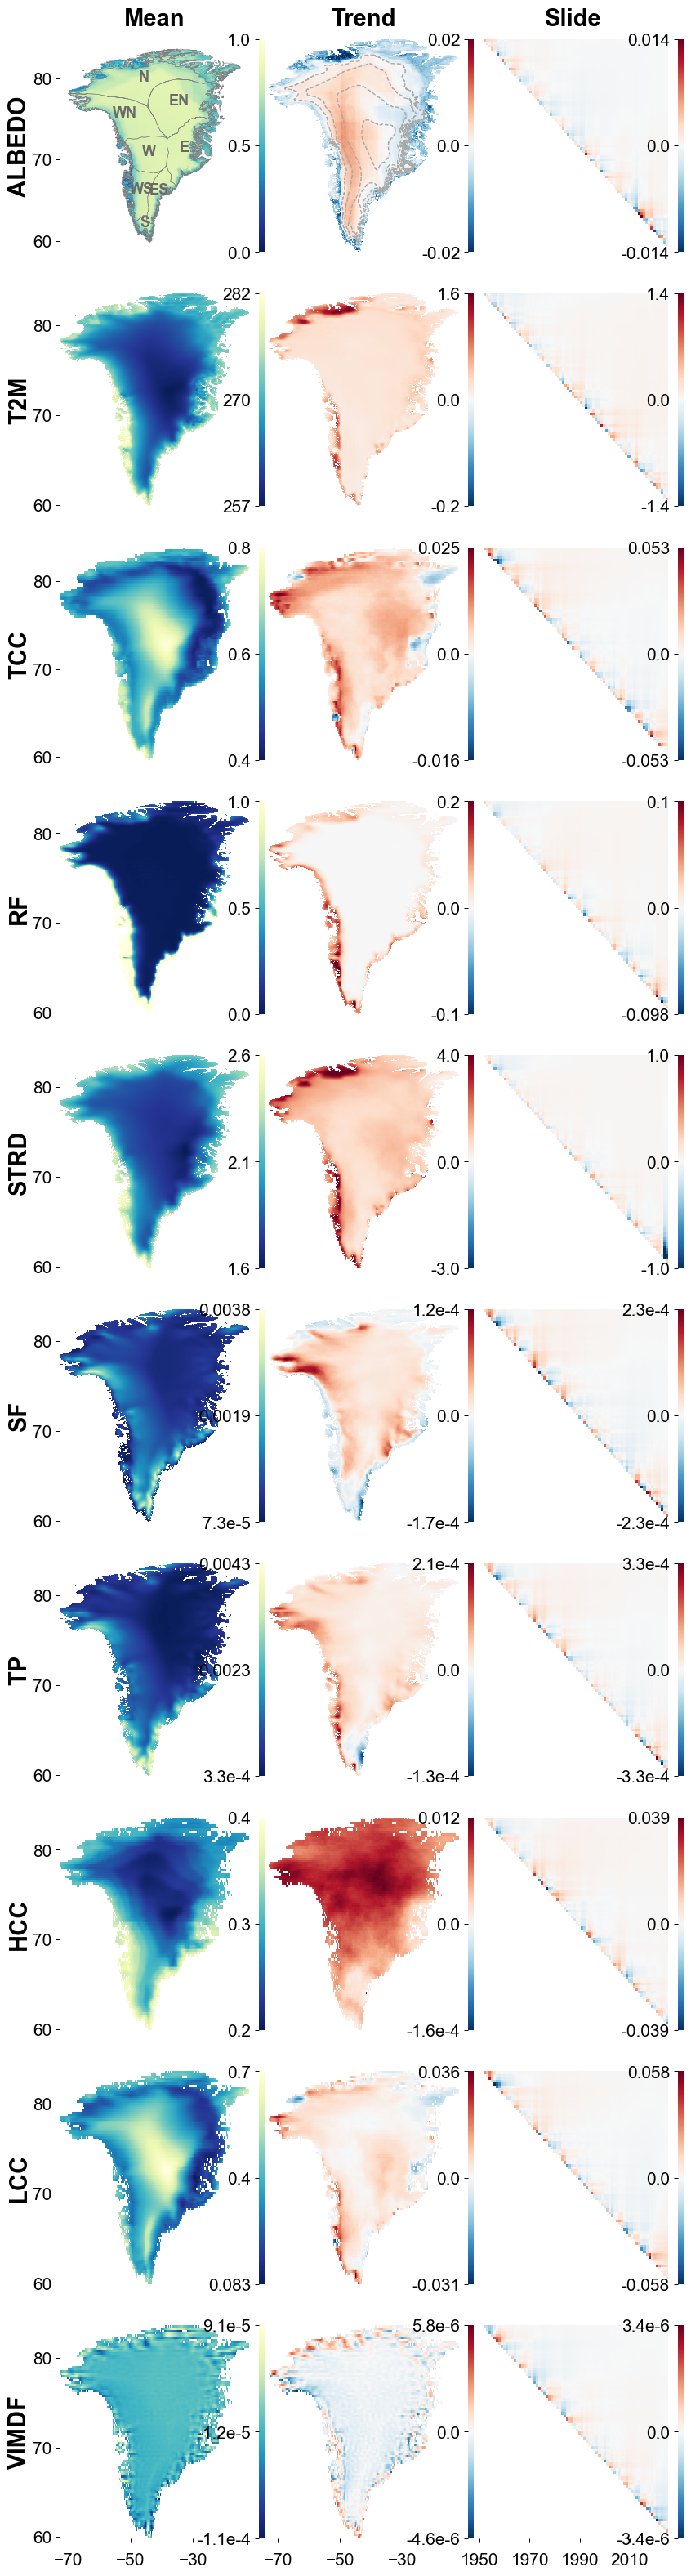

In [8]:
# -*- coding: utf-8 -*-
"""
Final 5×3 Greenland Climate Panel
(ALB fixed aspect ratio, no deformation, thicker contours)

【修改版 v7.3：统一 "Mean" 列配色为 'YlGnBu_r' (亮色代表高值)】
"""

import os
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm, Normalize, LinearSegmentedColormap
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.colors as mcolors
from shapely.geometry import LineString, MultiLineString

# ===== 参数区 =====
FONT_SIZE = 19
TICK_FONT_SIZE = FONT_SIZE - 4 # 15
TITLE_SIZE = FONT_SIZE + 2
HSPACE = 0.015
WSPACE = 0.03
TOP_ALIGN = 0.96
DATA_DIR = r"C:\greenland\1995bu\fig4"
SAVE_PATH = os.path.join(DATA_DIR, "Fig4_10x3panel_final_v7_ticks_refined.png") # (路径保持v7)

# shapefile路径
BASIN_DIR = r"C:\greenland\Greenland_shp\流域冰盖"
CONTOUR_PATH = r"C:\greenland\Greenland_shp\等间距等值线.shp"

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": FONT_SIZE,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.7,
    "ytick.major.width": 0.7
})

# ========== 加载 shapefile ==========
abbr_map = {
    "WestSouth": "WS", "WestNorth": "WN", "West": "W",
    "Melt": "M", "EastSouth": "ES", "EastNorth": "EN",
    "East": "E", "North": "N", "South": "S"
}

basins_list = []
for fname in os.listdir(BASIN_DIR):
    if fname.lower().endswith(".shp"):
        gdf = gpd.read_file(os.path.join(BASIN_DIR, fname))
        if gdf.crs and gdf.crs.to_string() != "EPSG:4326":
            gdf = gdf.to_crs("EPSG:4326")
        gdf["abbr"] = abbr_map.get(os.path.splitext(fname)[0], fname)
        basins_list.append(gdf)
basins_all = pd.concat(basins_list, ignore_index=True)

contour_gdf = gpd.read_file(CONTOUR_PATH)
if contour_gdf.crs and contour_gdf.crs.to_string() != "EPSG:4326":
    contour_gdf = contour_gdf.to_crs("EPSG:4326")

print(f"✅ Shapefiles loaded: {len(basins_all)} basins | {len(contour_gdf)} contours")

# ========== 图框布局 ==========
fig = plt.figure(figsize=(8.1, 33.6))

VARS = ["albedo", "t2m", "tcc", "rf", "strd",
        "sf", "tp", "hcc", "lcc", "vimdf"]
COL_NAMES = ["Mean", "Trend", "Slide"]

n_rows, n_cols = len(VARS), len(COL_NAMES)
left_margin, right_margin, bottom_margin = 0.05, 0.97, 0.05
total_width = right_margin - left_margin
available_width = total_width - (n_cols - 1) * WSPACE
w = available_width / n_cols
h = (TOP_ALIGN - bottom_margin - (n_rows - 1) * HSPACE) / n_rows
axes = []

PAD_TITLE = 12
PAD_XAXIS = 9

# ========== 绘图循环 ==========
for i, var in enumerate(VARS):
    for j, col in enumerate(COL_NAMES):
        left = left_margin + j * (w + WSPACE)
        bottom = TOP_ALIGN - (i + 1) * h - i * HSPACE
        ax = fig.add_axes([left, bottom, w, h])
        axes.append(ax)
        
        for spine in ax.spines.values():
            spine.set_visible(False)
        
        CBAR_WIDTH, CBAR_PAD = "3%", 0.08 

        meantrend_csv = os.path.join(DATA_DIR, f"Greenland_{var}_MeanTrend.csv")
        sliding_csv   = os.path.join(DATA_DIR, f"Greenland_{var}_SlidingTrend.csv")

        df = pd.read_csv(meantrend_csv).dropna(subset=["mean", "trend_per_decade"])
        mean_grid  = df.pivot(index="lat", columns="lon", values="mean").sort_index(ascending=True)
        trend_grid = df.pivot(index="lat", columns="lon", values="trend_per_decade").sort_index(ascending=True)
        mean_grid = mean_grid.reindex(sorted(mean_grid.columns), axis=1)
        trend_grid = trend_grid.reindex(sorted(trend_grid.columns), axis=1)
        lats, lons = mean_grid.index.values.astype(float), mean_grid.columns.values.astype(float)

        slide = pd.read_csv(sliding_csv, index_col=0)
        years, slide_years = slide.columns.astype(int).values, slide.index.astype(int).values
        vals = slide.to_numpy(dtype=float)
        mask = np.tril(np.ones_like(vals, dtype=bool), -1)
        vals_masked = np.ma.array(vals, mask=mask)
        
        label = ""

        # ================= ALBEDO =================
        if var == "albedo":
            # [!! 修正 !!] Mean 列统一使用 YlGnBu_r (反向)
            mean_cmap = plt.cm.YlGnBu_r 
            trend_cmap = plt.cm.RdBu_r
            if col == "Mean":
                im = ax.pcolormesh(lons, lats, mean_grid.values, cmap=mean_cmap,
                                   norm=Normalize(vmin=0, vmax=1), shading="auto")
                basins_all.boundary.plot(ax=ax, color="grey", linewidth=0.4, zorder=5)
                for _, row in basins_all.iterrows():
                    abbr = row["abbr"]
                    if abbr == "M": continue
                    x, y = row.geometry.centroid.x, row.geometry.centroid.y + 0.3
                    ax.text(x, y, abbr, fontsize=FONT_SIZE-6, color="dimgray",
                            ha="center", va="center", fontweight="bold", zorder=6)
                ax.set_aspect('auto', adjustable='box')
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_grid.values, cmap=trend_cmap,
                                   norm=TwoSlopeNorm(vmin=-0.02, vcenter=0, vmax=0.02), shading="auto")
                for geom in contour_gdf.geometry:
                    if isinstance(geom, (LineString, MultiLineString)): 
                        parts = [geom] if isinstance(geom, LineString) else geom.geoms
                        for part in parts:
                            xs, ys = part.xy
                            ax.plot(xs, ys, color="darkgrey", linestyle="--",
                                    linewidth=1.0, zorder=5)
                ax.set_aspect('auto', adjustable='box')
            else:
                vmax_slide = np.nanmax(np.abs(vals_masked))
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap=trend_cmap,
                                   norm=TwoSlopeNorm(vmin=-vmax_slide, vcenter=0, vmax=vmax_slide), shading="auto")
                ax.invert_yaxis()

        # ================= t2m =================
        elif var == "t2m":
            TREND_VMIN, TREND_VCENTER, TREND_VMAX = -0.2, 0.22, 1.6
            if col == "Mean":
                # [!! 修正 !!] Mean 列统一使用 YlGnBu_r
                im = ax.pcolormesh(lons, lats, mean_grid.values, cmap="YlGnBu_r", shading="auto")
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_grid.values, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=TREND_VMIN, vcenter=0, vmax=TREND_VMAX), shading="auto")
            else:
                vmax_slide = np.nanmax(np.abs(vals_masked))
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-vmax_slide, vcenter=0, vmax=vmax_slide), shading="auto")
                ax.invert_yaxis()

        # ================= tcc =================
        elif var == "tcc":
            if col == "Mean":
                # [!! 修正 !!] Mean 列统一使用 YlGnBu_r
                im = ax.pcolormesh(lons, lats, mean_grid.values, cmap="YlGnBu_r",
                                   norm=Normalize(vmin=np.nanmin(mean_grid), vmax=np.nanmax(mean_grid)), shading="auto")
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_grid.values, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=np.nanmin(trend_grid), vcenter=0, vmax=np.nanmax(trend_grid)), shading="auto")
            else:
                vmax_slide = np.nanmax(np.abs(vals_masked))
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-vmax_slide, vcenter=0, vmax=vmax_slide), shading="auto")
                ax.invert_yaxis()

        # ================= rf =================
        elif var == "rf":
            mean_scaled = mean_grid.values * 1e3
            trend_scaled = trend_grid.values * 1e3
            vals_masked *= 1e3
            if col == "Mean":
                # [!! 修正 !!] Mean 列统一使用 YlGnBu_r
                im = ax.pcolormesh(lons, lats, mean_scaled, cmap="YlGnBu_r",
                                   norm=Normalize(vmin=0, vmax=1), shading="auto")
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_scaled, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-0.1, vcenter=0, vmax=0.2), shading="auto")
            else:
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=np.nanmin(vals_masked), vcenter=0, vmax=np.nanmax(vals_masked)), shading="auto")
                ax.invert_yaxis()
        
        # ================= strd =================
        elif var == "strd":
            trend_grid_scaled = trend_grid / 1e5
            vals_masked_scaled = vals_masked / 1e6
            if col == "Mean":
                # [!! 修正 !!] Mean 列统一使用 YlGnBu_r
                im = ax.pcolormesh(lons, lats, mean_grid.values / 1e7, cmap="YlGnBu_r", shading="auto")
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_grid_scaled, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-3, vcenter=0, vmax=4), shading="auto")
            else:
                im = ax.pcolormesh(years, slide_years, vals_masked_scaled, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-1, vcenter=0, vmax=1), shading="auto")
                ax.invert_yaxis()

        # ================= (sf, tp, hcc, lcc, vimdf) =================
        else: 
            if col == "Mean":
                # [!! 修正 !!] Mean 列统一使用 YlGnBu_r
                im = ax.pcolormesh(lons, lats, mean_grid.values, cmap="YlGnBu_r", 
                                   norm=Normalize(vmin=np.nanmin(mean_grid), vmax=np.nanmax(mean_grid)),
                                   shading="auto")
            elif col == "Trend":
                im = ax.pcolormesh(lons, lats, trend_grid.values, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=np.nanmin(trend_grid), vcenter=0, vmax=np.nanmax(trend_grid)),
                                   shading="auto")
            else:
                vmax_slide = np.nanmax(np.abs(vals_masked))
                if vmax_slide == 0: vmax_slide = 1
                im = ax.pcolormesh(years, slide_years, vals_masked, cmap="RdBu_r",
                                   norm=TwoSlopeNorm(vmin=-vmax_slide, vcenter=0, vmax=vmax_slide),
                                   shading="auto")
                ax.invert_yaxis()

        # (三点刻度逻辑 保持 v2 修改)
        vmin = im.norm.vmin
        vmax = im.norm.vmax
        if hasattr(im.norm, 'vcenter'):
            vcenter = im.norm.vcenter
        else:
            vcenter = (vmin + vmax) / 2
        ticks_list = [vmin, vcenter, vmax]

        # ===== colorbar =====
        cb_ax = inset_axes(ax, width=CBAR_WIDTH, height="100%", loc='right',
                           bbox_to_anchor=(CBAR_PAD,0,1,1), bbox_transform=ax.transAxes, borderpad=0)
        
        cb = fig.colorbar(im, cax=cb_ax, ticks=ticks_list)
        cb.set_label("", fontsize=FONT_SIZE) 
        cb.outline.set_visible(False)
        cb.ax.tick_params(labelsize=TICK_FONT_SIZE) 
        cb.ax.yaxis.set_ticks_position('left')
        cb.ax.yaxis.set_label_position('left')
        
        # (刻度格式化 保持 v7 修改)
        formatted_ticks = []
        for t in ticks_list:
            if t == 0:
                s = "0.0"
            elif abs(t) >= 100:
                s = "{:.0f}".format(t)
            elif abs(t) >= 1:
                s = "{:.1f}".format(t)
            elif abs(t) < 0.001: 
                s = "{:.1e}".format(t)
            elif abs(t) < 0.1: 
                s = "{:.2g}".format(t)
            else:
                s = "{:.1f}".format(t)
            
            s = s.replace('e-0', 'e-').replace('e+0', 'e+')
            formatted_ticks.append(s)
        cb.set_ticklabels(formatted_ticks)
        
        # ===== 样式 =====
        ax.tick_params(labelsize=TICK_FONT_SIZE) 
        
        if i < n_rows - 1:
            ax.set_xticklabels([])
            ax.tick_params(bottom=False)
        else:
            if j < n_cols - 1: 
                ax.set_xticks([-70, -50, -30])
                ax.tick_params(axis='x', pad=PAD_XAXIS)
        
        if j > 0:
            ax.tick_params(left=False, labelleft=False)
        if i == 0:
            ax.set_title(col, fontsize=TITLE_SIZE, fontweight="bold", pad=PAD_TITLE)
        if j == 0:
            ax.text(-0.15, 0.5, var.upper(), transform=ax.transAxes,
                    fontsize=TITLE_SIZE, fontweight="bold",
                    va='center', ha='right', rotation=90)
            ax.set_yticks([60, 70, 80])

# ===== 底行年份刻度 =====
axes[-1].set_xticks(np.arange(1950, 2030, 20))
axes[-1].tick_params(labelsize=TICK_FONT_SIZE, axis='x', pad=PAD_XAXIS)

plt.savefig(SAVE_PATH, dpi=300, bbox_inches="tight")
plt.show()

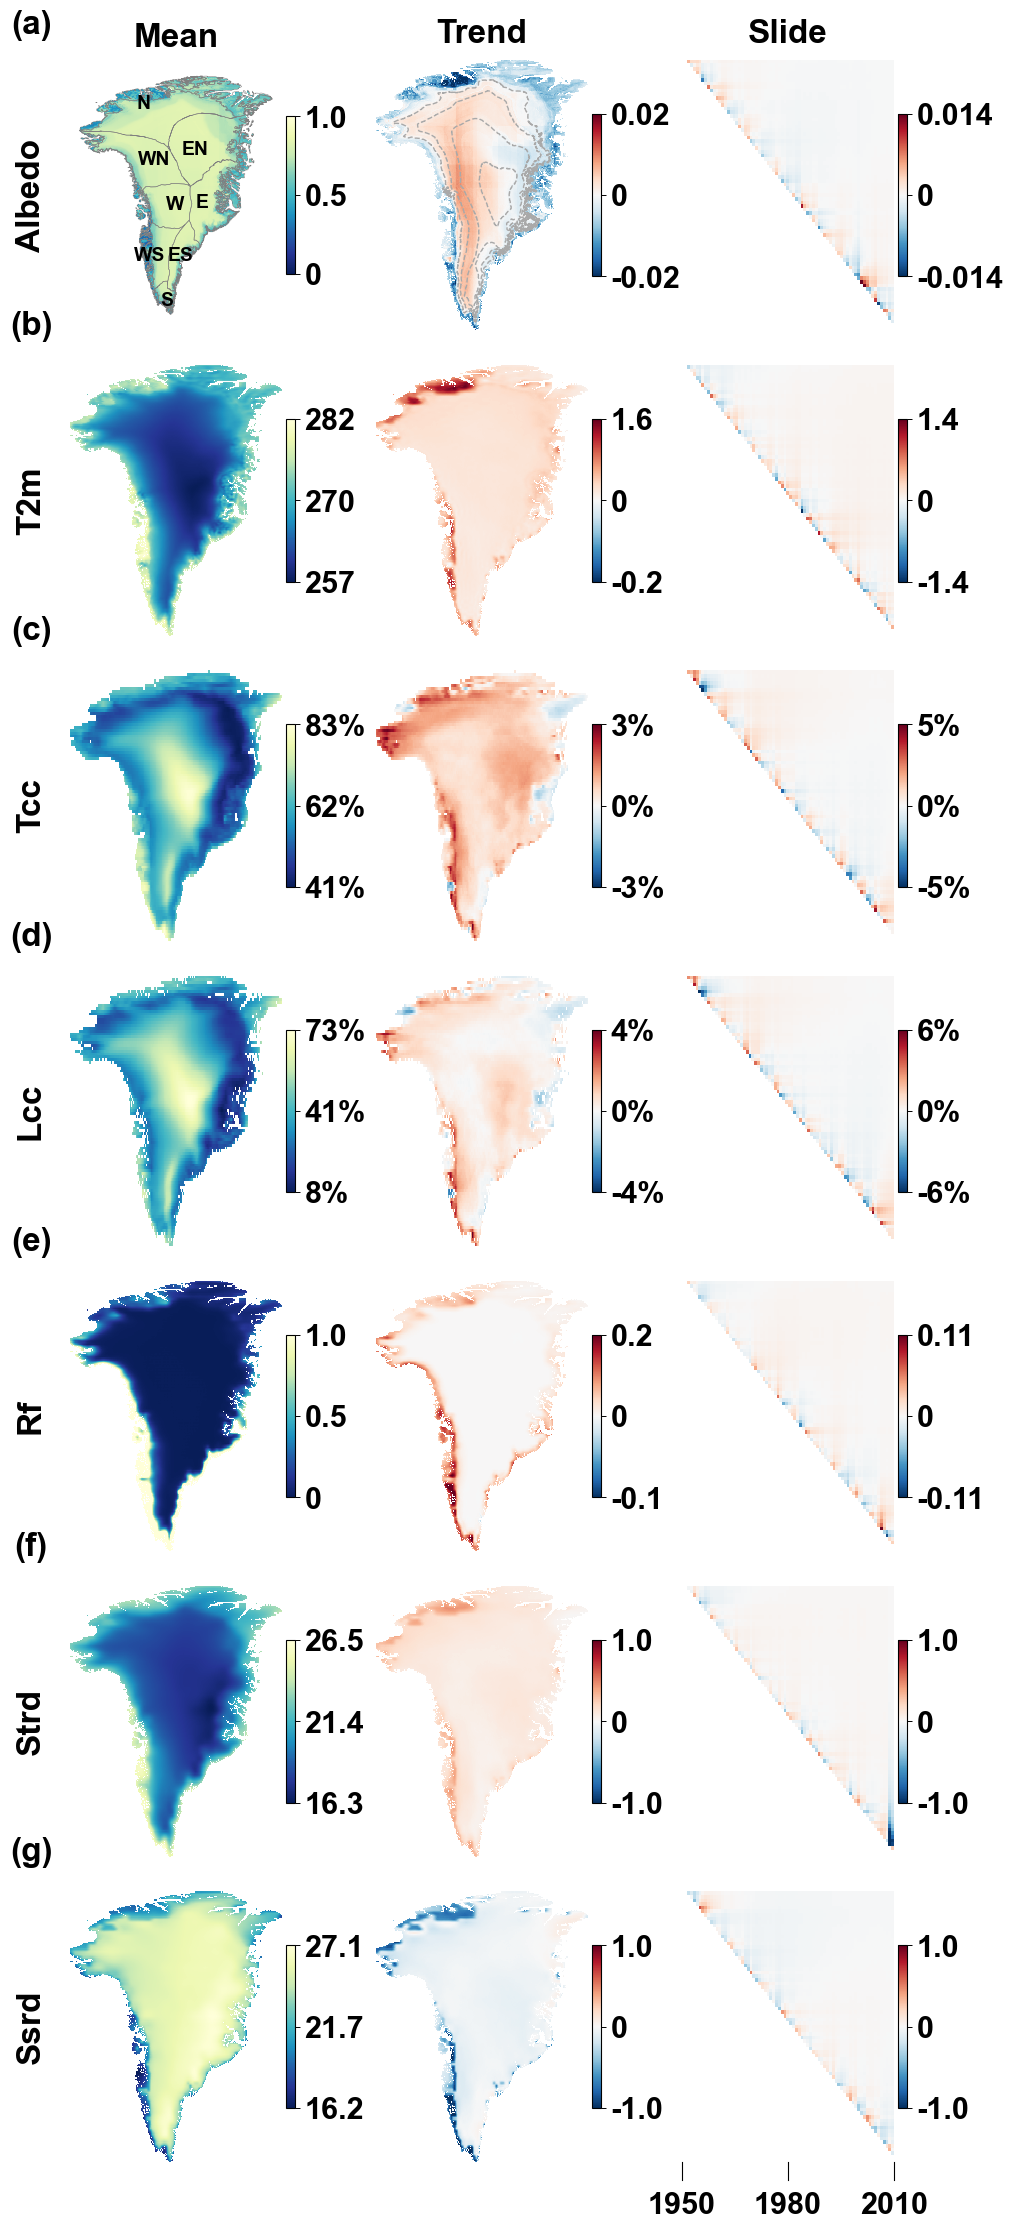

图像已保存：C:\greenland\1995bu\fig4\Fig4_npj_compact_v6.png


In [2]:
# -*- coding: utf-8 -*-
"""
Greenland Climate Panel (npj Style: 紧凑版 + 大图 + 手动对齐)
--------------------------------
- 手动指定三列的 X 轴位置，实现 Mean 右移
- 增大子图宽度 w，显著减少空白
- 色标紧贴子图右侧
- 严格的行高对齐
- T2m Mean 色标改为整数显示
- Strd Slide 色标范围锁定为 -1 到 1
- [修改] 年份标签上移 + 手动添加三根短刻度线
"""

import os
import sys
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import LineString, MultiLineString
from matplotlib.colors import TwoSlopeNorm, Normalize
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.lines import Line2D  # [新增] 用于绘制刻度线

# ====================== 基础参数 ======================
FONT_SIZE = 22
TICK_FONT_SIZE = FONT_SIZE 
TITLE_SIZE = FONT_SIZE + 2

# [核心调整] 布局参数
FIG_WIDTH_INCHES = 8.5   
FIG_HEIGHT_PER_ROW = 3.3 

# 子图尺寸
SUBPLOT_W = 0.25  
COL_X_POS = [0.06, 0.42, 0.78] 

TOP_ALIGN = 0.96   
BOTTOM_MARGIN = 0.05
HSPACE_ABS = 0.015 

DATA_DIR = r"C:\greenland\1995bu\fig4"
BASIN_DIR = r"C:\greenland\Greenland_shp\流域冰盖"
CONTOUR_PATH = r"C:\greenland\Greenland_shp\等间距等值线.shp"

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": FONT_SIZE,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.7,
    "ytick.major.width": 0.7,
})

# ====================== 加载数据 (保持不变) ======================
def load_basins():
    abbr_map = {
        "WestSouth": "WS", "WestNorth": "WN", "West": "W",
        "Melt": "M",
        "EastSouth": "ES", "EastNorth": "EN", "East": "E",
        "North": "N", "South": "S"
    }
    lst = []
    if not os.path.exists(BASIN_DIR):
        return gpd.GeoDataFrame()
    for fname in os.listdir(BASIN_DIR):
        if fname.lower().endswith(".shp"):
            gdf = gpd.read_file(os.path.join(BASIN_DIR, fname))
            gdf = gdf.to_crs("EPSG:4326")
            name = os.path.splitext(fname)[0]
            gdf["abbr"] = abbr_map.get(name, name)
            lst.append(gdf)
    if lst:
        return pd.concat(lst, ignore_index=True)
    return gpd.GeoDataFrame()

def load_contour():
    if not os.path.exists(CONTOUR_PATH):
        return gpd.GeoDataFrame()
    return gpd.read_file(CONTOUR_PATH).to_crs("EPSG:4326")

basins_all = load_basins()
contour_gdf = load_contour()

VARS_DESIRED = ["albedo", "t2m", "tcc", "lcc", "rf", "strd", "ssrd"]
DISPLAY = { "albedo": "Albedo", "t2m": "T2m", "tcc": "Tcc", "lcc": "Lcc", "rf": "Rf", "strd": "Strd", "ssrd": "Ssrd" }

VARS_PRESENT = []
if os.path.exists(DATA_DIR):
    for v in VARS_DESIRED:
        if os.path.exists(os.path.join(DATA_DIR, f"Greenland_{v}_MeanTrend.csv")):
            VARS_PRESENT.append(v)
else:
    sys.exit()

if not VARS_PRESENT: sys.exit()

# ====================== 工具函数 ======================
def make_grid(meantrend_csv):
    df = pd.read_csv(meantrend_csv).dropna(subset=["mean", "trend_per_decade"])
    mean = df.pivot(index="lat", columns="lon", values="mean").sort_index(ascending=True)
    trend = df.pivot(index="lat", columns="lon", values="trend_per_decade").sort_index(ascending=True)
    mean = mean.reindex(sorted(mean.columns), axis=1)
    trend = trend.reindex(sorted(trend.columns), axis=1)
    return mean, trend, mean.index.values.astype(float), mean.columns.values.astype(float)

def make_slide(slide_csv):
    df = pd.read_csv(slide_csv, index_col=0)
    vals = df.to_numpy(dtype=float)
    mask = np.tril(np.ones_like(vals, dtype=bool), -1)
    return np.ma.array(vals, mask=mask), df.index.astype(int), df.columns.astype(int)

def draw_contours(ax):
    if contour_gdf.empty: return
    for geom in contour_gdf.geometry:
        if isinstance(geom, LineString):
            xs, ys = geom.xy
            ax.plot(xs, ys, "darkgrey", linestyle="--", linewidth=1.0)
        elif isinstance(geom, MultiLineString):
            for p in geom.geoms:
                xs, ys = p.xy
                ax.plot(xs, ys, "darkgrey", linestyle="--", linewidth=1.0)

def draw_basins(ax):
    if basins_all.empty: return
    basins_all.boundary.plot(ax=ax, color="grey", linewidth=0.4, zorder=5)
    text_props = dict(fontsize=FONT_SIZE - 8, fontweight="bold", color="black", ha="center", va="center", zorder=10)
    for _, row in basins_all.iterrows():
        label = row["abbr"]
        if label == "M": continue
        pt = row.geometry.representative_point()
        x, y = pt.x, pt.y
        dx = dy = 0.0
        if label == "WS": dx = -3.3
        elif label == "WN": dx = 1.0
        elif label == "W": dx = 1.5
        elif label == "N": dy = 1.5
        elif label == "S": dy = -0.5
        elif label == "E": dx = -0.8
        elif label == "EN": dx = -1.0
        elif label == "ES": dx = 1
        ax.text(x + dx, y + dy, label, **text_props)

def draw_colorbar(fig, ax, im, var, col_name):
    cax = inset_axes(
        ax,
        width="4%",           
        height="60%",         
        loc="center left",    
        bbox_to_anchor=(1.02, 0., 1, 1), 
        bbox_transform=ax.transAxes,
        borderpad=0
    )

    cb = fig.colorbar(im, cax=cax)

    vmin = im.norm.vmin
    vmax = im.norm.vmax
    if hasattr(im.norm, "vcenter"):
        vc = im.norm.vcenter
    else:
        vc = 0.5 * (vmin + vmax)

    ticks = [vmin, vc, vmax]
    if abs(vmin) < 1e-9 and abs(vmax) < 1e-9: ticks = [0]
    
    cb.set_ticks(ticks)
    
    labels = []
    for v in ticks:
        if var == "t2m" and col_name == "Mean":
            labels.append(f"{int(round(v))}") 
        elif var in ["tcc", "lcc"]:
            labels.append(f"{v * 100:.0f}%")
        else:
            if abs(v) < 1e-3 and v != 0: s = f"{v:.1e}"
            elif abs(v) < 1: s = f"{v:.2g}"
            else: s = f"{v:.1f}"
            labels.append(s)
            
    cb.set_ticklabels(labels)
    cb.ax.tick_params(labelsize=TICK_FONT_SIZE)
    for lb in cb.ax.get_yticklabels():
        lb.set_fontweight("bold")

# ====================== 主绘图逻辑 ======================
n_rows = len(VARS_PRESENT)
COLS = ["Mean", "Trend", "Slide"]

FIG_HEIGHT = FIG_HEIGHT_PER_ROW * n_rows
fig = plt.figure(figsize=(FIG_WIDTH_INCHES, FIG_HEIGHT))

available_h = TOP_ALIGN - BOTTOM_MARGIN - (n_rows - 1) * HSPACE_ABS
h = available_h / n_rows

axes = []
row_first_axes = [None] * n_rows

for i, var in enumerate(VARS_PRESENT):
    mean_file = os.path.join(DATA_DIR, f"Greenland_{var}_MeanTrend.csv")
    slide_file = os.path.join(DATA_DIR, f"Greenland_{var}_SlidingTrend.csv")
    
    mean_grid, trend_grid, lats, lons = make_grid(mean_file)
    slide_vals, slide_rows, slide_cols = make_slide(slide_file)

    bottom = TOP_ALIGN - (i + 1) * h - i * HSPACE_ABS

    for j, col in enumerate(COLS):
        left = COL_X_POS[j]
        ax = fig.add_axes([left, bottom, SUBPLOT_W, h])
        axes.append(ax)
        
        if j == 0: row_first_axes[i] = ax
        for sp in ax.spines.values(): sp.set_visible(False)

        # ===== 绘图 =====
        if col == "Mean":
            if var == "albedo": im = ax.pcolormesh(lons, lats, mean_grid.values, cmap="YlGnBu_r", norm=Normalize(vmin=0, vmax=1), shading="auto")
            elif var == "rf": im = ax.pcolormesh(lons, lats, mean_grid.values * 1e3, cmap="YlGnBu_r", norm=Normalize(vmin=0, vmax=1), shading="auto")
            elif var in ["strd", "ssrd"]: im = ax.pcolormesh(lons, lats, mean_grid.values / 1e6, cmap="YlGnBu_r", shading="auto")
            else: im = ax.pcolormesh(lons, lats, mean_grid.values, cmap="YlGnBu_r", shading="auto")
            if i == 0: draw_basins(ax)

        elif col == "Trend":
            if var == "albedo":
                norm = TwoSlopeNorm(vmin=-0.02, vcenter=0.0, vmax=0.02)
                im = ax.pcolormesh(lons, lats, trend_grid.values, cmap="RdBu_r", norm=norm, shading="auto")
                draw_contours(ax)
            elif var == "t2m": im = ax.pcolormesh(lons, lats, trend_grid.values, cmap="RdBu_r", norm=TwoSlopeNorm(vmin=-0.2, vcenter=0.0, vmax=1.6), shading="auto")
            elif var == "rf": im = ax.pcolormesh(lons, lats, trend_grid.values * 1e3, cmap="RdBu_r", norm=TwoSlopeNorm(vmin=-0.1, vcenter=0.0, vmax=0.2), shading="auto")
            elif var in ["strd", "ssrd"]: im = ax.pcolormesh(lons, lats, trend_grid.values / 1e6, cmap="RdBu_r", norm=TwoSlopeNorm(vmin=-1, vcenter=0.0, vmax=1), shading="auto")
            else:
                data = trend_grid.values
                vabs = np.nanmax(np.abs(data)) if np.any(np.isfinite(data)) else 1.0
                if vabs == 0: vabs = 1.0
                im = ax.pcolormesh(lons, lats, data, cmap="RdBu_r", norm=TwoSlopeNorm(vmin=-vabs, vcenter=0.0, vmax=vabs), shading="auto")

        else:  # Slide
            if var == "rf": vals = slide_vals * 1e3
            elif var in ["strd", "ssrd"]: vals = slide_vals / 1e6
            else: vals = slide_vals
            
            vabs = np.nanmax(np.abs(vals)) if vals.size > 0 else 1.0
            if vabs == 0 or not np.isfinite(vabs): vabs = 1.0
            
            if var == "strd":
                norm = TwoSlopeNorm(vmin=-1, vcenter=0.0, vmax=1)
            elif var == "ssrd" and vabs < 1: 
                norm = TwoSlopeNorm(vmin=-1, vcenter=0.0, vmax=1)
            else: 
                norm = TwoSlopeNorm(vmin=-vabs, vcenter=0.0, vmax=vabs)

            im = ax.pcolormesh(slide_cols, slide_rows, vals, cmap="RdBu_r", norm=norm, shading="auto")
            ax.invert_yaxis()

        draw_colorbar(fig, ax, im, var, col)
        ax.set_xticks([])
        ax.set_yticks([])

        if i == 0:
            ax.set_title(col, fontsize=TITLE_SIZE, fontweight="bold", pad=12)

# ====================== 标签绘制 ======================
x_label_pos = 0.015 
for i, var in enumerate(VARS_PRESENT):
    ax0 = row_first_axes[i]
    if ax0 is None: continue
    
    pos = ax0.get_position()
    y_mid = pos.y0 + pos.height / 2.0
    y_top = pos.y1 + 0.01

    fig.text(
        x_label_pos, y_mid, DISPLAY[var],
        fontsize=TITLE_SIZE, fontweight="bold",
        rotation=90, ha="center", va="center"
    )
    fig.text(
        x_label_pos, y_top, f"({chr(97 + i)})",
        fontsize=TITLE_SIZE, fontweight="bold",
        ha="center", va="bottom"
    )

# ====================== 年份刻度与标签 (手动绘制) ======================
if axes:
    last_ax = axes[-1]
    
    # 获取最后一个子图的位置信息
    bbox = last_ax.get_position()
    x0, y0 = bbox.x0, bbox.y0
    w = bbox.width
    
    # 设置刻度参数
    tick_len = 0.008       # 刻度线长度 (Figure 坐标系)
    text_pad = 0.005       # 文字与刻度下端的距离
    
    # 定义三个刻度的位置: 左边、中间、右边
    tick_x_list = [x0, x0 + w/2, x0 + w]
    tick_labels = ["1950", "1980", "2010"]
    
    # 绘制
    for tx, label in zip(tick_x_list, tick_labels):
        # 1. 绘制刻度线 (Line2D)
        # xdata=[tx, tx], ydata=[y0, y0 - tick_len]
        line = Line2D(
            [tx, tx], [y0, y0 - tick_len],
            transform=fig.transFigure, # 使用 Figure 坐标系，绝对定位
            color="black", 
            linewidth=0.8, # 与 axes.linewidth 保持一致
            linestyle="-"
        )
        fig.add_artist(line)
        
        # 2. 绘制文字 (居中对齐于刻度)
        fig.text(
            tx, 
            y0 - tick_len - text_pad, 
            label, 
            fontsize=TICK_FONT_SIZE, 
            fontweight="bold", 
            ha="center", # 居中对齐
            va="top"     # 顶部对齐 (紧贴刻度)
        )

SAVE_PATH = os.path.join(DATA_DIR, f"Fig4_npj_compact_v6.png")
plt.savefig(SAVE_PATH, dpi=300, bbox_inches="tight")
plt.show()
print(f"图像已保存：{SAVE_PATH}")